# APAU 2026 - Marketing Effectiveness

Predecir si un cliente de un banco contrata un depósito a plazo (`Expected`: 0 o 1).
Métrica de Kaggle: Macro F1. Algoritmo secreto: `VotingClassifier`.

Equipo: Álvaro Vázquez, Luis Vázquez y Sergio Yela

## 1. Conocimiento del dominio

Antes de mirar los datos, creemos que influyen:
- El resultado de la campaña anterior (`poutcome`, `previous`, `pdays`): si ya dijo que sí, es más probable que vuelva a decir que sí.
- La situación económica (`euribor3m`, `nr.employed`, `emp.var.rate`).
- La edad y el trabajo (jubilados y estudiantes).
- El tipo de contacto (`contact`) y el mes (`month`).
- Tener préstamos (`housing`, `loan`): quien debe dinero ahorra menos.
- `campaign`: llamar muchas veces al mismo cliente probablemente no ayuda.

No usamos `duration` (duración de la llamada) porque solo se sabe cuando la llamada ya ha terminado.

**Cargar los datos.** Abrimos los dos ficheros: uno con clientes de los que ya sabemos si contrataron el depósito (para aprender) y otro con clientes nuevos (para predecir).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("train.csv")
test = pd.read_csv("test_nolabel.csv")
print(train.shape, test.shape)
train.head()

(36188, 22) (5000, 21)


,Id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,Expected
0,44dc8df9,35,admin.,married,high.school,unknown,no,no,telephone,jul,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,0
1,3f62aa06,52,technician,married,basic.9y,no,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.967,5228.1,0
2,34bd6148,44,blue-collar,single,basic.9y,no,no,no,cellular,may,...,4,999,1,failure,-1.8,92.893,-46.2,1.244,5099.1,0
3,e1671cba,35,admin.,married,high.school,no,yes,yes,telephone,jun,...,9,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,0
4,c20477f0,33,technician,married,university.degree,no,yes,no,cellular,jul,...,7,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,0


**Revisar los datos.** Comprobamos que no falten valores y qué porcentaje de clientes contrata el depósito.

In [2]:
print("Nulos:", train.isna().sum().sum())
print()
print(train["Expected"].value_counts(normalize=True))

Nulos: 0

Expected
0    0.887725
1    0.112275
Name: proportion, dtype: float64


**Gráficas de la campaña anterior, el tipo de contacto y el mes.** Vemos en qué casos contratan más clientes.

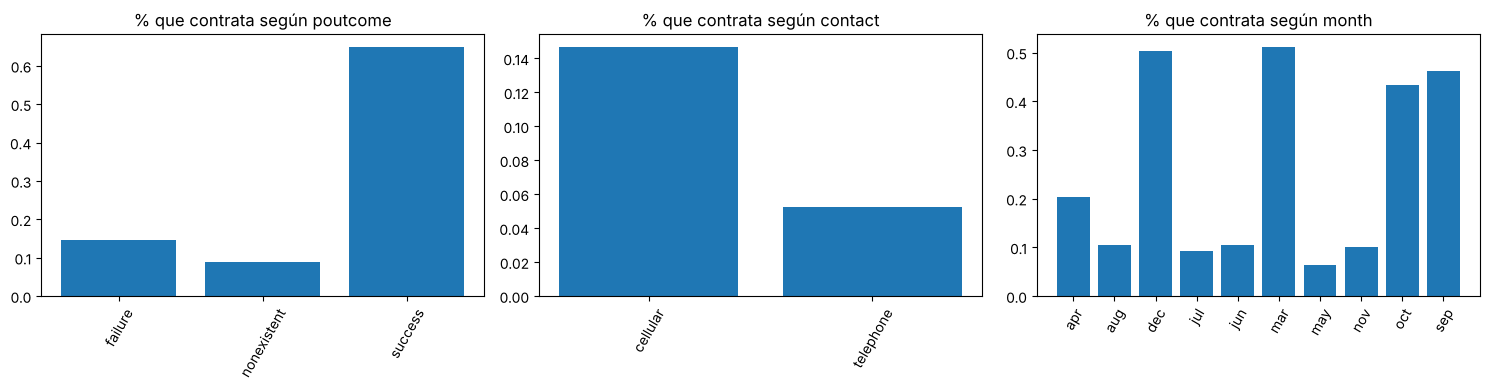

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["poutcome", "contact", "month"]):
    t = train.groupby(col)["Expected"].mean()
    a.bar(t.index, t.values)
    a.set_title("% que contrata según " + col)
    a.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

**Más comparaciones.** Vemos si contratan más según el trabajo, la situación económica (euribor) y la edad.

In [4]:
print(train.groupby("job")["Expected"].mean().round(3).sort_values())
print()
print(train.groupby(pd.cut(train["euribor3m"], [0, 1, 2, 4, 6]))["Expected"].mean().round(3))
print()
print(train.groupby(pd.cut(train["age"], [0, 25, 35, 55, 65, 100]))["Expected"].mean().round(3))

job
blue-collar      0.069
services         0.079
entrepreneur     0.086
self-employed    0.102
housemaid        0.103
technician       0.108
management       0.112
unknown          0.113
admin.           0.129
unemployed       0.138
retired          0.253
student          0.308
Name: Expected, dtype: float64

euribor3m
(0, 1]    0.459
(1, 2]    0.157
(2, 4]    0.091
(4, 6]    0.048
Name: Expected, dtype: float64

age
(0, 25]      0.204
(25, 35]     0.117
(35, 55]     0.085
(55, 65]     0.150
(65, 100]    0.472
Name: Expected, dtype: float64


**Preparar los datos.** Quitamos la duración de la llamada (no se conoce antes de llamar), convertimos las categorías en números y ponemos todas las cifras en una escala parecida para que los modelos las comparen bien.

In [5]:
from sklearn.preprocessing import StandardScaler

y = train["Expected"]
X = train.drop(columns=["Id", "Expected", "duration"])
X_test = test.drop(columns=["Id", "duration"])

for d in (X, X_test):
    d["contactado_antes"] = (d["pdays"] != 999).astype(int)
    d["pdays"] = d["pdays"].replace(999, 0)

todo = pd.get_dummies(pd.concat([X, X_test]))
X = todo.iloc[:len(X)]
X_test = todo.iloc[len(X):]

scaler = StandardScaler()
X = scaler.fit_transform(X)
X_test = scaler.transform(X_test)
print(X.shape)

(36188, 63)


**Crear los modelos.** Guardamos una parte de los datos para comprobar los resultados. Montamos tres modelos (KNN, árbol de decisión y regresión logística) y los combinamos en uno que decide por votación. También definimos cómo elegir a partir de qué probabilidad damos un cliente como "sí contrata".

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import f1_score

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

knn = KNeighborsClassifier(n_neighbors=51)
arbol = DecisionTreeClassifier(max_depth=6, min_samples_leaf=40, random_state=0)
logreg = LogisticRegression(max_iter=2000)
voting = VotingClassifier([("knn", knn), ("arbol", arbol), ("logreg", logreg)], voting="soft")

umbrales = np.arange(0.05, 0.60, 0.01)
def mejor_umbral(prob):
    mejor_f1, mejor_u = 0, 0.5
    for u in umbrales:
        f1 = f1_score(y_val, prob >= u, average="macro")
        if f1 > mejor_f1:
            mejor_f1, mejor_u = f1, u
    return mejor_f1, mejor_u

**Ajustar los modelos sueltos.** Probamos distintos valores del KNN y del árbol de decisión para ver con cuáles salen mejores resultados.

In [7]:
for k in [5, 15, 51, 101]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    f1, u = mejor_umbral(m.predict_proba(X_val)[:, 1])
    print("k =", k, "-> Macro F1:", round(f1, 4))

print()
for prof in [3, 6, 12, 20]:
    m = DecisionTreeClassifier(max_depth=prof, min_samples_leaf=40, random_state=0).fit(X_tr, y_tr)
    f1, u = mejor_umbral(m.predict_proba(X_val)[:, 1])
    print("profundidad =", prof, "-> Macro F1:", round(f1, 4))

k = 5 -> Macro F1: 0.6706


k = 15 -> Macro F1: 0.6894


k = 51 -> Macro F1: 0.7


k = 101 -> Macro F1: 0.699

profundidad = 3 -> Macro F1: 0.7063


profundidad = 6 -> Macro F1: 0.7205


profundidad = 12 -> Macro F1: 0.7152


profundidad = 20 -> Macro F1: 0.7141


**Comparar los modelos.** Entrenamos KNN, árbol y votación, y vemos cuánto mejora cada uno al elegir bien el punto de corte en lugar de usar 0,5.

In [8]:
mejores = {}

for nombre, modelo in [("KNN", knn), ("Árbol", arbol), ("Voting", voting)]:
    modelo.fit(X_tr, y_tr)
    prob = modelo.predict_proba(X_val)[:, 1]

    f1_05 = f1_score(y_val, prob >= 0.5, average="macro")
    mejor_f1, mejor_u = mejor_umbral(prob)
    mejores[nombre] = mejor_u
    print(nombre, "| con 0.5:", round(f1_05, 4), "| mejor:", round(mejor_f1, 4), "con umbral", round(mejor_u, 2))

KNN | con 0.5: 0.6304 | mejor: 0.7 con umbral 0.22


Árbol | con 0.5: 0.6646 | mejor: 0.7205 con umbral 0.18


Voting | con 0.5: 0.6287 | mejor: 0.7215 con umbral 0.25


**Dos formas de votar.** Comparamos votar con la decisión de cada modelo y votar con sus probabilidades, con y sin ajustar el punto de corte.

In [9]:
hard = VotingClassifier([("knn", knn), ("arbol", arbol), ("logreg", logreg)], voting="hard")
hard.fit(X_tr, y_tr)
print("Voting hard (umbral fijo):", round(f1_score(y_val, hard.predict(X_val), average="macro"), 4))

voting.fit(X_tr, y_tr)
print("Voting soft con 0.5      :", round(f1_score(y_val, voting.predict(X_val), average="macro"), 4))
print("Voting soft mejor umbral :", round(mejor_umbral(voting.predict_proba(X_val)[:, 1])[0], 4))

Voting hard (umbral fijo): 0.6432


Voting soft con 0.5      : 0.6287


Voting soft mejor umbral : 0.7215


**Predicción final.** Entrenamos el modelo con todos los datos, predecimos los clientes nuevos y guardamos el resultado en un fichero para subirlo a Kaggle.

In [10]:
voting.fit(X, y)
prob_test = voting.predict_proba(X_test)[:, 1]
pred = (prob_test >= mejores["Voting"]).astype(int)

sub = pd.DataFrame({"Id": test["Id"], "Predicted": pred})
sub.to_csv("submission.csv", index=False)
print(sub.shape, "| % de 1 predichos:", round(pred.mean(), 3))
sub.head()

(5000, 2) | % de 1 predichos: 0.132


,Id,Predicted
0,897212bf,0
1,2ad6d4ae,1
2,a193003e,0
3,3f639630,0
4,dfe76b9d,0


## Conclusiones

- Se cumplen las hipótesis sobre el resultado de la campaña anterior, el contexto económico, el trabajo y la edad, y el tipo de contacto. No se cumple la de los préstamos (`housing`, `loan`): no influyen.
- Solo el 11 % de los clientes contrata (clases desbalanceadas).
- Macro F1 en validación con el mejor umbral: KNN 0,700, árbol 0,7205 y Voting 0,7215. Con el umbral 0,5 quedan en 0,630, 0,665 y 0,629.
- Ajustar el umbral mejora el Macro F1 más que cambiar de modelo.
- Árbol y Voting quedan casi iguales, y KNN algo por debajo.
- No se usa `duration`, porque no se conoce antes de llamar al cliente.
- Score en Kaggle: público 0,69368 y privado 0,71792. El privado se parece al de validación (0,7215); el público es más bajo, y se calcula con solo una parte del test.